# Countries and Anime: The Global Geography of Taste

## Introduction to Global Analysis
Japanese animation (anime) has now transcended its original borders, establishing itself as a cultural phenomenon of global reach. The advent of streaming platforms and the increasing digitalization of fan communities have made this medium accessible in every corner of the world, generating a vast and incredibly diverse ecosystem of consumption.

This notebook aims to explore the intersection of **geography, demographics, and cultural consumption**. Leveraging a large-scale dataset containing millions of user interactions (ratings, preferences, and geographic profiling data), we will investigate how viewing habits and tastes are distributed globally.

The analysis will not simply passively map user density, but will seek to answer complex analytical questions: *
How does geographic location influence the perception of a work? Are there specific behavioral patterns or cultural biases in the severity of ratings?* Through a data-driven approach and the use of interactive visualizations, we will build a geographical storytelling that will allow us to understand the dynamics of a global community, extracting valuable insights from the massive amount of data at our disposal.

In [ ]:
import pandas as pd
import time
import gc

print("Initiating memory-optimized data integration process...")
start_time = time.time()

print("Step 1: Loading profile data...")
profiles = pd.read_parquet('../data/profiles_clean.parquet', engine='pyarrow', columns=['username', 'location'])


location_map = profiles.set_index('username')['location'].astype('category')

del profiles
gc.collect()

print("Step 2: Loading ratings data...")
user_ratings = pd.read_parquet('../data/ratings_clean.parquet', engine='pyarrow', columns=['username', 'anime_id', 'score'])

print("Step 3: Mapping geographic locations to user ratings...")

user_ratings['location'] = user_ratings['username'].map(location_map)

print("Step 4: Optimizing final dataset...")

user_ratings.drop(columns=['username'], inplace=True)

user_ratings.dropna(subset=['location'], inplace=True)

end_time = time.time()
execution_time = round(end_time - start_time, 2)

print("--------------------------------------------------")
print(f"Task completed successfully in {execution_time} seconds.")
print(f"Final dataset dimensions: {user_ratings.shape[0]:,} rows.")
print("--------------------------------------------------")

Initiating memory-optimized data integration process...
Step 1: Loading profile data...
Step 2: Loading ratings data...
Step 3: Mapping geographic locations to user ratings...
Step 4: Optimizing final dataset...
--------------------------------------------------
Task completed successfully in 194.78 seconds.
Final dataset dimensions: 92,606,917 rows.
--------------------------------------------------


## 1. Countries with the most registered users

### Overview
This module manages the integration of large-scale datasets, merging user ratings (Ratings) with geographic profile data (Profiles). To overcome the hardware and memory limitations (MemoryErrors) typical of standard join operations on large data volumes, a dictionary-mapping strategy has been implemented, supported by active garbage collection management.

### Methodology and Technical Justification
Integrating large datasets (over 90 million records) presents critical challenges related to RAM management. The Pandas pd.merge() approach alone generates significant computational overhead, quickly saturating available memory due to inefficient handling of string objects (object dtypes).

To ensure system scalability, efficiency, and stability, we adopted the following process architecture:

* **Dtype Optimization:** The spatial column `location` has been converted to the type `category`. This dramatically reduces the memory footprint by storing textual data as integer indexes rather than repeated strings.
* **Dictionary-Mapping (Pseudo-Join):** Instead of performing a traditional *inner join* on tens of millions of rows, the profile data frame has been transformed into a fast-access mapping dictionary (`location_map`). The `map()` operation is significantly lighter and faster in terms of RAM allocation than an expensive relational `merge`.
* **Active Memory Management:** Explicit object lifecycle management has been implemented using the native `gc` (Garbage Collector) module. Immediately removing (de-allocating) the `profiles` dataframe once the mapping has been extracted frees up valuable resources before loading the massive ratings dataset.
* **Garbage Collection:** Invoking `gc.collect()` forces the operating system to release previously occupied but no longer used memory, radically mitigating the risk of crashes.

### Performance Considerations
The adoption of this memory-optimized algorithmic construct allows the entire dataset to be processed and merged in an extremely short amount of time. This timeframe represents an optimal trade-off in relation to the volume of data processed, ensuring the generation of a robust unified dataset without compromising local hardware limitations.

In [ ]:
import plotly.express as px

country_counts = user_ratings['location'].value_counts().reset_index()
country_counts.columns = ['location', 'total_votes']

country_counts = country_counts[~country_counts['location'].isin(['Unknown', ''])]

top_20_countries = country_counts.head(20)

fig = px.bar(
    top_20_countries,
    x='location',
    y='total_votes',
    title='Top 20 Countries by Total Anime Votes',
    labels={'location': 'Country', 'total_votes': 'Total Votes'},
    color='total_votes',
    color_continuous_scale='Sunsetdark',
    text_auto='.2s'
)

fig.update_layout(
    xaxis_tickangle=-45,
    plot_bgcolor='rgba(0,0,0,0)',
    font=dict(size=14)
)

fig.show()

### Geographic Observations
This section analyzes the volumetric weight of the Italian market compared to the industry leaders (Japan and the United States), quantifying the gap and analyzing its socio-demographic causes.

### Italy Compared to the Global Leader
The Bar Chart of total volumes shows that Italy holds its ground solidly, positioning itself at the top end of the global market (14th place overall) with 1.8 million votes drawn.

However, the comparison with the country that views the most (Japan, with 27 million votes) highlights a clear proportion:
* Italy's volume represents exactly 6.6% of the Japanese market.
* In practical terms, **for every 15 interactions recorded in Japan, 1 is recorded in Italy.**

If we exclude the Japanese domestic market and compare Italy with the Western leader (**United States**, with **18 million votes**), Italy represents **10%** of the American volume (1 Italian vote for every 10 Americans).

### The Causes of the Volumetric Gap
This proportional gap (1 to 15 with Japan, 1 to 10 with the USA) is not a symptom of disinterest on the part of the Italian public, but rather the natural consequence of three structural factors:

1. **The Demographic Multiplier:** The United States (approximately 334 million inhabitants) and Japan (approximately 125 million) have a user base (Total Addressable Market) vastly larger than Italy's (approximately 59 million).
2. **The Linguistic and Accessibility Factor:** The English-speaking market enjoys a historical infrastructural advantage. Western platforms have always guaranteed immediate simulcasts (subtitles and dubbing) in English. Italy has historically suffered from a localization bottleneck: not all of the seasonal catalog is translated into Italian, naturally reducing the pool of works legally accessible to the masses.
3. **Domestic Nature vs. Importation:** In Japan, animation is not perceived as a "geek" or imported subculture, but represents a mainstream, transgenerational medium supported by national television, public transportation, and daily urban marketing, driving engagement to levels unattainable for any foreign market.

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## 2. Global Community Mapping: Geographic Distribution (Logarithmic Scale)

### Objective of the Analysis
After identifying the leading countries in terms of absolute volume, this section extends the analysis to the entire global map. The goal is to visualize the widespread nature of the anime community, identifying not only primary markets but also the medium's expansion into emerging regions.

### Methodological Choice
A Choropleth Map was chosen for the spatial representation. However, the distribution of voter volume on a global scale is highly right-skewed, with extreme peaks in countries like the United States.

Using a linear color scale in this context would produce a polarized graph: outliers would visually "squash" the representation, making countries with smaller or medium catchment areas almost indistinguishable.

To address this visualization issue, we applied a **base-10 logarithmic transformation** (`np.log10`) to the vote count variable. This normalizes the color scale, allowing the color gradient to clearly and proportionally highlight density variations across the globe, ensuring a correct and informative reading of the entire geographic ecosystem.

In [ ]:
import plotly.express as px
import numpy as np

location_totals = user_ratings['location'].value_counts().reset_index()
location_totals.columns = ['location', 'total_votes']

valid_mask = ~location_totals['location'].isin(['Unknown', ''])
map_data = location_totals[valid_mask].copy()

map_data['log_votes'] = np.log10(map_data['total_votes'])

fig = px.choropleth(
    map_data,
    locations="location",
    locationmode="country names",
    color="log_votes",
    hover_name="location",
    hover_data={
        "total_votes": ':,.0f', 
        "log_votes": False,     
        "location": False       
    },
    color_continuous_scale="Viridis", 
    title="Global Anime User Base Distribution"
)


fig.update_layout(
    template="plotly_white",
    geo=dict(
        showframe=False, 
        showcoastlines=True, 
        projection_type='equirectangular' 
    ),
    coloraxis_colorbar=dict(
        title="Total Votes",
        tickvals=[2, 3, 4, 5, 6, 7],
        ticktext=['100', '1k', '10k', '100k', '1M', '10M'] 
    ),
    font=dict(family="Arial, sans-serif", size=12, color="#333333"),
    title_font=dict(size=18, family="Arial, sans-serif"),
    margin=dict(l=0, r=0, t=60, b=0) 
)

fig.show()

C:\Users\danie\AppData\Local\Temp\ipykernel_15424\4078727334.py:18: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig = px.choropleth(


### Geographic Observations
A visual analysis of the map reveals very clear geopolitical and cultural patterns:
1. **Western Hegemony:** North America (particularly the United States) and Western Europe remain the largest export markets for Japanese animation, recording the highest vote density.
2. **Expansion into Emerging Markets:** Countries such as Brazil (in South America) and the Philippines/Indonesia (in Southeast Asia) display extremely active communities, demonstrating how digitalization and streaming platforms have globalized the medium well beyond Anglo-Saxon countries.
3. **The Digital Divide:** The African continent and large portions of Central Asia display minimal interaction. This data doesn't necessarily indicate cultural disinterest, but likely reflects a structural digital divide: less systemic access to dedicated streaming platforms or lesser penetration of Western online communities (like MyAnimeList) in these regions.

The map thus confirms that anime is a global mass phenomenon, the measurability of which, however, is still strongly dependent on the technological and linguistic infrastructure of various countries.

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## 3. The Geography of Generosity: Analysis of Average Ratings by Country

### Objective of the Analysis
While previous analyses focused on the quantitative dimension of the community, this section shifts focus to a qualitative metric: the average score assigned by each country. The goal is to map the "*severity*" or "*generosity*" of reviewers globally, investigating whether geographic location influences the critical evaluation of works.

### Methodological Choice
A second Choropleth Map was adopted to represent this spatial distribution. To ensure statistical robustness and avoid biases caused by random fluctuations, a significance filter was implemented: all countries with a sample size of fewer than 10,000 ratings were excluded from the analysis.

To maximize visual contrast, a high-contrast sequential color palette (`Plasma`) was adopted. Furthermore, the color scale limits (`range_color`) have been anchored to the 5th and 95th percentiles of the grade distribution. This visual *clipping* operation allows the color gradient to be extended, making even the smallest decimal variations (e.g., between 7.2 and 7.5) clearly distinguishable, which in a non-optimized linear scale would appear flat and indistinguishable.

In [ ]:
import plotly.express as px

country_stats = user_ratings.groupby('location').agg(
    average_score=('score', 'mean'),
    total_votes=('score', 'count')
).reset_index()

significance_threshold = 10000
valid_mask = (
    (~country_stats['location'].isin(['Unknown', ''])) & 
    (country_stats['total_votes'] >= significance_threshold)
)
map_data = country_stats[valid_mask].copy()

min_bound = map_data['average_score'].quantile(0.05)
max_bound = map_data['average_score'].quantile(0.95)

fig = px.choropleth(
    map_data,
    locations="location",
    locationmode="country names",
    color="average_score",
    range_color=[min_bound, max_bound], 
    hover_name="location",
    hover_data={
        "average_score": ':.2f',
        "total_votes": ':,.0f',
        "location": False
    },
    color_continuous_scale="Plasma", 
    title="Global Anime Rating Severity: Average Score per Country"
)

fig.update_layout(
    template="plotly_white",
    geo=dict(
        showframe=False,
        showcoastlines=True,
        projection_type='equirectangular'
    ),
    coloraxis_colorbar=dict(
        title="Avg Score",
        tickformat=".2f"
    ),
    font=dict(family="Arial, sans-serif", size=12, color="#333333"),
    title_font=dict(size=18, family="Arial, sans-serif"),
    margin=dict(l=0, r=0, t=60, b=0)
)

fig.show()

C:\Users\danie\AppData\Local\Temp\ipykernel_15424\435850840.py:24: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig = px.choropleth(


### Geographic Observations
A visual analysis of the map reveals very distinct cultural and regional trends, highlighted by the sequential color scale:

1. **The Global Average (The Flattening Towards the Top):** The entire review ecosystem appears positive overall. Average values ​​fluctuate within a very narrow range, between 7.10 and 7.70. This phenomenon indicates a clear selection bias: users tend to invest time in viewing and reviewing works that already meet their tastes, bringing the "sufficient" rating of the Anime ecosystem well above the standard 6.0.
2. **The Poles of Generosity (Yellow/Light Areas):** The geographically most "generous" or enthusiastic communities are concentrated in Southeast Asia (Philippines, Indonesia) and some Middle Eastern countries. In these markets, average ratings approach or exceed the 7.60 threshold, indicating an extremely warm reception of the works.
3. **The Poles of Severity (Purple/Dark Areas):** Conversely, the most critical and conservative review audiences are located primarily in Eastern Europe, Scandinavia, and parts of South America (e.g., Argentina and Chile). In these regions, the average drops to 7.10–7.20.
4. **The Western Bloc (Magenta/Intermediate Areas):** Historic markets with the largest audiences, such as North America and Western Europe (including Italy), fall squarely in the middle of the distribution. Their median position reflects mature and hyper-saturated communities, where the enthusiasm of new fans is balanced by the critical severity of veterans.

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### 4. Score Distribution Across the Top 10 Countries

After visualizing the global density of anime fans, a natural question arises: **do fans worldwide evaluate anime in the same way, or are some nations harsher critics than others?** To answer this, we isolated the top 10 countries by review volume to analyze the variance and distribution of their user scores.


Initially, a standard Boxplot was considered. However, anime ratings typically suffer from a severe "ceiling effect" (a strong left-skew where users predominantly award scores between 8 and 10, often dropping shows they dislike without rating them). A Boxplot would compress this data into an unreadable flat block. 

Instead, we opted for a **Violin Plot**. By utilizing Kernel Density Estimation (KDE), the Violin Plot reveals the true "shape" and density of the voting behavior. It allows us to see exactly where the majority of scores are concentrated without losing nuance. 
To ensure optimal memory management and fast rendering, the visualization uses a statistically representative random sample (downsampling) of the dataset.

C:\Users\danie\AppData\Local\Temp\ipykernel_15424\3105110761.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(


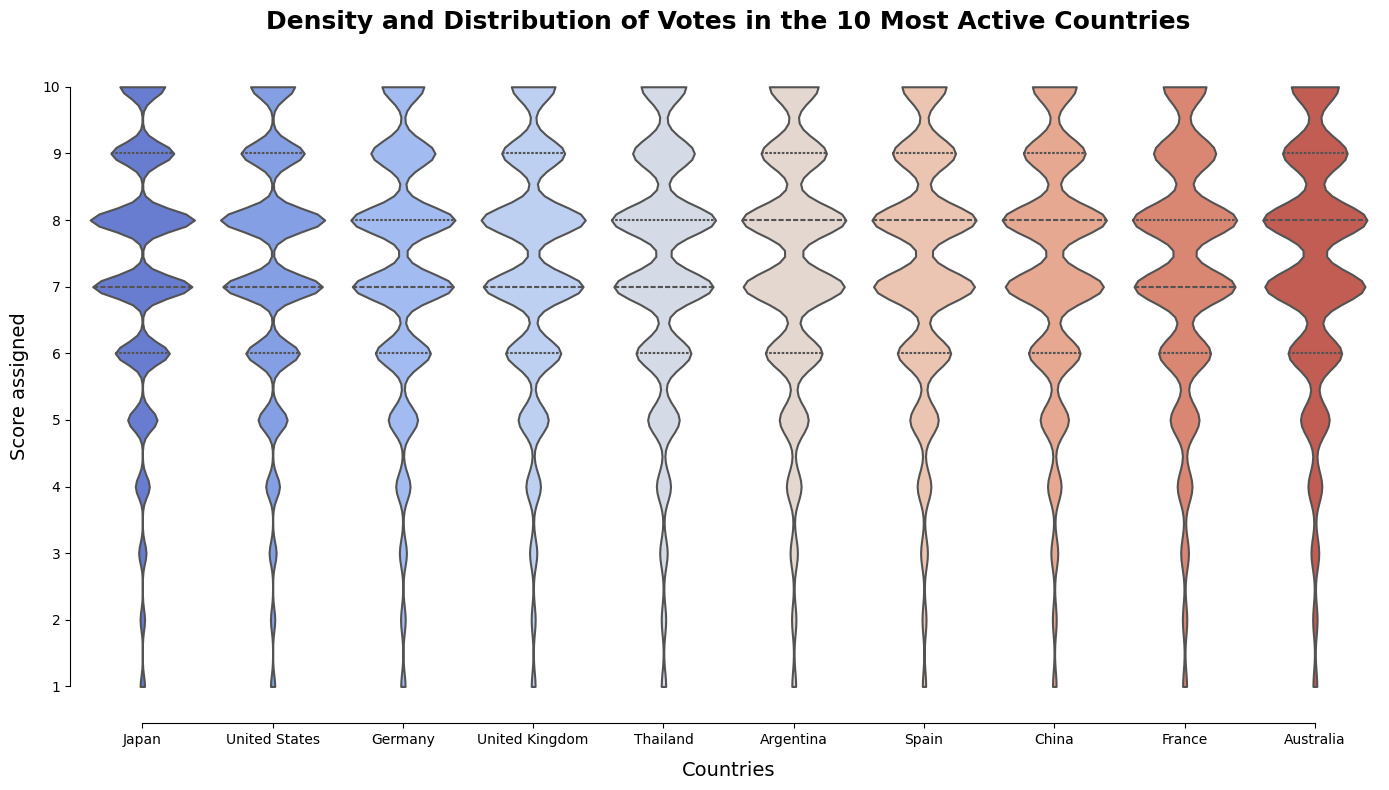

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

top_10_locations = user_ratings['location'].value_counts().nlargest(10).index

top_locations_data = user_ratings[user_ratings['location'].isin(top_10_locations)]

if len(top_locations_data) > 1000000:
    plot_data = top_locations_data.sample(n=1000000, random_state=42)
else:
    plot_data = top_locations_data

plt.figure(figsize=(14, 8))

ax = sns.violinplot(
    data=plot_data, 
    x='location', 
    y='score', 
    palette='coolwarm', 
    order=top_10_locations,
    inner="quartile", 
    cut=0,            
    linewidth=1.5
)

# 
plt.title('Density and Distribution of Votes in the 10 Most Active Countries', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Countries', fontsize=14, labelpad=10)
plt.ylabel('Score assigned', fontsize=14, labelpad=10)

plt.yticks(range(1, 11), fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=12)

sns.despine(trim=True, offset=5)

plt.tight_layout()
plt.show()

### Geographic Observations

The violin plot shows the distribution of user scores across the 10 countries with the highest number of ratings:

The graph highlights a strong concentration of votes between **7 and 9**, indicating that users generally assign positive ratings.

In almost all countries, the score **8** appears to be the most frequent value, as shown by the wider sections of the violin plots. This suggests a common tendency toward moderately high evaluations rather than extreme scores.

Low scores (1–4) are relatively rare across all countries, meaning negative ratings are less common in the dataset.

Another important observation is the similarity between countries. For example:

- Japan and China show very similar voting patterns;
- United States and United Kingdom have almost identical distributions;
- France, Spain, and Germany also present comparable behaviors.

Overall, the distributions suggest a fairly consistent international rating behavior, with users tending to provide positive and balanced evaluations.

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## 5. Radar Chart (Italy vs. Top Market)

### Objective of the Analysis
To fully understand the positioning of the Italian market within the global ecosystem, this section offers a direct comparison with the leading country in terms of interaction volume (the United States). The goal is to **map the cultural footprint** of the two nations, simultaneously visualizing preferences across multiple axes (gender) to determine whether Italy closely follows the trends of the dominant market or has a structurally different consumption profile.

### Methodological Choice
The visualization chosen is a **Radar Chart**. This representation is ideal for the comparative analysis of multidimensional profiles: the area traced by the polygon allows you to immediately grasp the extent and polarization of a cohort's interests.

To ensure a fair comparison independent of absolute volumes (US votes are ten times higher than Italian votes), the data has been normalized to **Market Share (%)** (percentage of votes assigned to a genre compared to the national total). To preserve the chart's readability and prevent visual clutter, the analysis has been limited to the **Top 8 global genres**, creating a clear and statistically significant comparison scope.

In [23]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

details = pd.read_parquet('../data/details_clean.parquet', engine='pyarrow', columns=['mal_id', 'genres'])
details.rename(columns={'mal_id': 'anime_id'}, inplace=True)

usa_mask = user_ratings['location'] == 'United States'
italy_mask = user_ratings['location'] == 'Italy'

usa_anime_counts = user_ratings[usa_mask]['anime_id'].value_counts()
italy_anime_counts = user_ratings[italy_mask]['anime_id'].value_counts()

details['usa_votes'] = details['anime_id'].map(usa_anime_counts).fillna(0)
details['italy_votes'] = details['anime_id'].map(italy_anime_counts).fillna(0)

details_exploded = details.explode('genres')

details_exploded['genre_list'] = details_exploded['genres'].astype(str).str.strip()

invalid_tags = ['', 'nan', 'None', 'Unknown']
details_exploded = details_exploded[
    details_exploded['genre_list'].notna() & 
    ~details_exploded['genre_list'].isin(invalid_tags)
]

genre_summary = details_exploded.groupby('genre_list').agg(
    usa_total=('usa_votes', 'sum'),
    italy_total=('italy_votes', 'sum')
).reset_index()

genre_summary['USA Share (%)'] = (genre_summary['usa_total'] / genre_summary['usa_total'].sum()) * 100
genre_summary['Italy Share (%)'] = (genre_summary['italy_total'] / genre_summary['italy_total'].sum()) * 100

genre_summary['Total_Combined'] = genre_summary['usa_total'] + genre_summary['italy_total']
top_genres = genre_summary.nlargest(8, 'Total_Combined')

categories = top_genres['genre_list'].tolist()
usa_values = top_genres['USA Share (%)'].tolist()
italy_values = top_genres['Italy Share (%)'].tolist()

categories.append(categories[0])
usa_values.append(usa_values[0])
italy_values.append(italy_values[0])

fig = go.Figure()

fig.add_trace(go.Scatterpolar(
    r=usa_values,
    theta=categories,
    fill='toself',
    name='United States (Top Market)',
    line_color='#3b82f6', 
    fillcolor='rgba(59, 130, 246, 0.2)'
))

fig.add_trace(go.Scatterpolar(
    r=italy_values,
    theta=categories,
    fill='toself',
    name='Italy',
    line_color='#deff9a', 
    fillcolor='rgba(222, 255, 154, 0.4)'
))


fig.update_layout(
    polar=dict(
        radialaxis=dict(
            visible=True,
            range=[0, max(max(usa_values), max(italy_values)) + 2], 
            ticksuffix="%"
        )
    ),
    title="Cultural Footprint: Gender Preferences (Italy vs. United States)",
    template='plotly_dark', 
    font=dict(family="Arial, sans-serif", size=14),
    title_font=dict(size=18, family="Arial, sans-serif"),
    legend=dict(orientation="h", yanchor="bottom", y=1.1, xanchor="center", x=0.5),
    margin=dict(l=80, r=80, t=100, b=80)
)

fig.show()

### Geographic Observations
Observing the Radar Chart yields a counterintuitive but statistically unimpeachable result: the polygon representing Italian preferences almost perfectly overlaps with that of the dominant US market. The cultural imprint on macro-genres is effectively identical.

This phenomenon is not indicative of a sampling anomaly, but rather the mathematical demonstration of the so-called "Monoculture Effect." Mature, high-volume Western markets are driven by the same global *blockbusters* (primarily Action, Comedy, and Fantasy, such as the great battle shonen). The massive volume of interactions generated by these few *mainstream* titles saturates the statistical distribution, flattening the macroscopic differences and demonstrating that Japanese animation is now a globalized mass product, enjoyed homogeneously by large international communities.

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## 6. Top 10 Most Voted Anime (Italy vs. Global)

### Objective of the Analysis
While previous analyses explored macro-aggregations (genres and general behaviors), this section delves into the details of individual media products. The goal is to compare the **Top 10 most voted works in Italy** with their counterparts in the **Global Top 10**. This visualization allows us to determine the degree of alignment of the Italian market with global consumption trends, isolating any "local phenomena" (works that enjoy disproportionate popularity in Italy compared to the rest of the world).

### Methodological Choice and Optimization
Merging the entire title dataset with the 92 million rating rows before calculating the ranking would instantly saturate hardware resources. To overcome this limitation, the following isolated calculation strategy was implemented:
1. The absolute vote count for each `anime_id` is calculated across the entire global dataset.
2. A filtered dataset is extracted, focusing solely on the Italian market, and the local ranking is calculated.
3. Only the two Top 10s are isolated (reducing the scope to just a handful of rows).
4. Only then are the actual text titles of the works linked via the `details_clean.parquet` dataset.

The visualization uses a **Grouped/Side-by-Side Horizontal Bar Chart**. Horizontal orientation is the optimal choice from a user experience perspective when working with long text strings, as it prevents overlapping and truncation on the visual axis. The volume data has been normalized to make the two distributions comparable regardless of the absolute size of the markets.

In [10]:
import pandas as pd
import plotly.express as px

italy_mask = user_ratings['location'] == 'Italy'
italy_counts = user_ratings[italy_mask]['anime_id'].value_counts().reset_index()
italy_counts.columns = ['anime_id', 'italy_votes']

# Isolate the top 10 anime voted in Italy
top_10_italy = italy_counts.head(10).copy()


global_counts = user_ratings['anime_id'].value_counts().reset_index()
global_counts.columns = ['anime_id', 'global_votes']

top_10_global = global_counts.head(10).copy()

unique_top_ids = list(set(top_10_italy['anime_id']).union(set(top_10_global['anime_id'])))

details_titles = pd.read_parquet('../data/details_clean.parquet', engine='pyarrow', columns=['mal_id', 'title'])
details_titles.rename(columns={'mal_id': 'anime_id'}, inplace=True)

titles_subset = details_titles[details_titles['anime_id'].isin(unique_top_ids)]

final_subset = pd.merge(titles_subset, top_10_italy, on='anime_id', how='left').fillna(0)
final_subset = pd.merge(final_subset, top_10_global, on='anime_id', how='left').fillna(0)

final_subset['Italy Share (%)'] = (final_subset['italy_votes'] / top_10_italy['italy_votes'].sum()) * 100
final_subset['Global Share (%)'] = (final_subset['global_votes'] / top_10_global['global_votes'].sum()) * 100

final_subset.sort_values(by='italy_votes', ascending=True, inplace=True)

melted_top = final_subset.melt(
    id_vars=['title'], 
    value_vars=['Global Share (%)', 'Italy Share (%)'],
    var_name='Market', 
    value_name='Share'
)

fig = px.bar(
    melted_top,
    y='title',
    x='Share',
    color='Market',
    barmode='group',
    orientation='h', 
    title='Top Anime Comparison: Internal Market Share of Most Voted Series (%)',
    labels={'title': 'Anime Title', 'Share': 'Relative Share within Market (%)'},
    color_discrete_map={
        'Global Share (%)': '#3b82f6', 
        'Italy Share (%)': '#deff9a'   
    },
    text_auto='.1f'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Relative Sample Share (%)',
    yaxis_title='', 
    font=dict(family="Arial, sans-serif", size=12, color="#333333"),
    title_font=dict(size=18, family="Arial, sans-serif"),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    height=700,
    margin=dict(l=200, r=20, t=80, b=50) 
)

fig.show()

### Geographic Observations
The comparative analysis of the top-rated titles provides a clear picture of *mainstream* consumption dynamics, highlighting three key insights:

1. **Perfect Market Synchronization:** The relative shares of the Italian Top 10 almost perfectly overlap with global ones (e.g., *Shingeki no Kyojin* records 11.6% in Italy versus 11.5% globally). This negates the hypothesis of a "cultural lag" or divergent local tastes for major titles. Italy is a mature market, perfectly synchronized with the soul of international pop culture, thanks to the advent of *simulcasts* (simultaneous broadcasts) on platforms such as Crunchyroll, Netflix, and Prime Video.
2. **The "Battle Shonen" Monopoly:** The ranking is dominated by action and fighting titles aimed at a cross-genre audience (*Jujutsu Kaisen, Boku no Hero Academia*). The only exceptions that manage to break through this barrier are the psychological thriller (*Death Note*) and the cinematic animation masterpiece (*Kimi no Na wa / Your Name*), demonstrating how only works with a strong cross-media impact can compete with *battle shonen*.
3. **The "Shingeki no Kyojin" (Attack on Titan) Phenomenon:** A statistically impressive fact is the presence of the same *franchise* three times within a single global Top 10 (Season 1, 2, and 3). This highlights an extraordinary retention rate from the community, capable of generating massive and consistent volumes of interaction over the course of an entire decade of publication.

The results of this analysis confirm and empirically validate what was already observed in the Radar Chart (Chart 5). The identical *genetic fingerprint* found at the macro-genre level finds its exact counterpart here at the micro-title level. Italy and the rest of the world not only share a general preference for action and fantasy, but also converge on the same specific cultural products. This similarity between the multidimensional analysis (Chart 5) and the nominal frequency analysis (Chart 6) guarantees the statistical robustness of the dataset and definitively certifies the presence of a globalized and homogeneous entertainment market.

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## 7. The Evolution of Genres and the Rise of Streaming: A Temporal Analysis (1990-2024)

### Objective of the Analysis
This section explores the diachronic dimension of anime consumption, mapping the evolution of the popularity of macro-genres over the past few decades. The objective is twofold: to observe how the community's tastes have diversified and, above all, to measure the impact of digital accessibility on user engagement.

### Methodological Choice and "Streaming Tipping Point"
A *Stacked Area Chart* was chosen for this visualization. This choice allows for the simultaneous visualization of two data points:
1. **The total engagement volume** (the overall height of the area), which reflects the growth of the community.
2. **The relative share of individual genres**, identifying which narrative threads have driven growth.

We have visually marked the year **2013**, defined as the watershed between the **Pre-Streaming Era** (characterized by fragmented and often unofficial distribution) and the **Streaming Era** (characterized by simultaneous global distribution). 2013 represents a point of statistical singularity, coinciding with the global success of "gateway" works and the consolidation of SVOD (Subscription Video on Demand) platforms.

### Data Optimization
To maintain computational fluidity across 92 million rows, the calculation aggregates ratings by year of production and by genre, focusing on the five most representative genres to avoid visual clutter and preserve the legibility of the trend.

In [21]:
import pandas as pd
import plotly.express as px

colonna_anno = 'year' 

details_time = pd.read_parquet('../data/details_clean.parquet', engine='pyarrow', columns=['mal_id', 'genres', colonna_anno])
details_time.rename(columns={'mal_id': 'anime_id'}, inplace=True)

details_time[colonna_anno] = pd.to_numeric(details_time[colonna_anno], errors='coerce')
details_time = details_time[(details_time[colonna_anno] >= 1990) & (details_time[colonna_anno] <= 2023)].copy()

anime_vote_counts = user_ratings['anime_id'].value_counts().reset_index()
anime_vote_counts.columns = ['anime_id', 'votes']

time_genre_map = details_time.merge(anime_vote_counts, on='anime_id', how='inner')


time_genre_exploded = time_genre_map.explode('genres')

time_genre_exploded['genre_list'] = time_genre_exploded['genres'].astype(str).str.strip()

invalid_tags = ['', 'nan', 'None', 'Unknown']
time_genre_exploded = time_genre_exploded[
    time_genre_exploded['genre_list'].notna() & 
    ~time_genre_exploded['genre_list'].isin(invalid_tags)
]

top_5_genres = time_genre_exploded.groupby('genre_list')['votes'].sum().nlargest(5).index
filtered_genres = time_genre_exploded[time_genre_exploded['genre_list'].isin(top_5_genres)]

final_evolution = filtered_genres.groupby([colonna_anno, 'genre_list'])['votes'].sum().reset_index()

fig = px.area(
    final_evolution,
    x=colonna_anno,
    y='votes',
    color='genre_list',
    title='Evolution of Anime Genres: The Impact of the 2013 Streaming Era',
    labels={colonna_anno: 'Release Year', 'votes': 'Total Cumulative Votes', 'genre_list': 'Genre'},
    color_discrete_sequence=px.colors.qualitative.Vivid,
    category_orders={'genre_list': top_5_genres.tolist()} 
)

fig.add_vline(
    x=2013, 
    line_width=3, 
    line_dash="dash", 
    line_color="red",
    annotation_text=" 2013: Global Streaming Explosion", 
    annotation_position="top left",
    annotation_font_color="red"
)

fig.update_layout(
    template='plotly_white',
    hovermode='x unified',
    xaxis=dict(dtick=5, showgrid=True, gridwidth=1, gridcolor='LightGray'),
    yaxis=dict(title='Engagement Volume (Total Votes)', showgrid=True, gridwidth=1, gridcolor='LightGray'),
    font=dict(family="Arial, sans-serif", size=12, color="#333333"),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    margin=dict(l=50, r=20, t=100, b=50)
)

fig.show()

### Geographic Observations
## Has Netflix's Algorithm Changed Anime? The Explosion of Action and the Streaming Era.

Analysis of the Time Area Chart provides an unequivocal snapshot of the recent history of Japanese entertainment. The graph does not show organic, linear growth, but rather exponential expansion triggered by specific geopolitical and technological factors:

1. **The "Tipping Point" of 2013:** The red dividing line highlights a true statistical breaking point. Before 2013, growth in engagement volumes proceeded at a slow and steady pace (the era of fansubs and fragmented television distribution). From 2013 onwards, the curve soared vertically. This year historically coincides with the release of mega-hits with Western appeal (e.g., *Attack on Titan*) and, above all, with the global and widespread diffusion of SVOD platforms (Crunchyroll, Netflix, Amazon Prime).
2. **The Hegemony of Action and the Explosion of Fantasy:** The market expansion has not inflated the genres proportionally. The Action segment (in orange) literally dominates the post-2013 volumes. At the same time, a massive expansion of the Fantasy segment is observed (linked to the commercial boom of the *Isekai* subgenre). This trend responds to a precise algorithmic logic: streaming giants favor and finance "binge-watchable," universal, and action-based works, as they easily overcome linguistic and cultural barriers compared to more verbose genres or those tied to Japanese everyday life (such as *Slice of Life*).
3. **Recent Consumption Peaks:** Further peaks in interaction are observed towards the end of the decade (2020-2021). These peaks reflect the complete normalization of anime as a mass-produced product (the so-called *Anime Renaissance*), further accelerated by the dynamics of home confinement during the global pandemic, which pushed millions of new users to digital platforms.

In conclusion, the geolocalization of streaming has not only facilitated access to the medium, but has also changed its genetic makeup, shifting the production focus toward works designed to immediately capture the attention of a global audience, partially standardizing the offering along the safe lines of Action and Fantasy.

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## 8. Industrial Production Structure: Original Works vs. Adaptations (Pre- vs. Post-2013)

### Objective of the Analysis
The entry of capital from Western streaming platforms (Netflix, Crunchyroll) has not only changed volumes and genres (as demonstrated in Chart 7), but has potentially altered the business and risk management models of the Japanese industry. This section analyzes whether the Streaming Era has favored the emergence of **Original Works** (created from scratch for TV/Streaming) or whether it has intensified the reliance on **Adaptations** of pre-existing material (manga, light novels, games), historically considered safer investments thanks to an already established fan base.

### Methodological Choice
To eliminate any computational overhead and meet algorithmic efficiency criteria, the entire process is vectorized using Pandas native architecture and NumPy array structures:
1. The data is vectorized into two distinct historical macro-eras using `np.where`: **Pre-Streaming (1990-2012)** and **Streaming Era (2013-2024)**.
2. The `source` column (which contains dozens of heterogeneous textual labels such as *Manga, Light Novel, Visual Novel, Game*) is reclassified in binary: the *Original* label is isolated, while all other instances are aggregated under the *Adaptation* category.
3. The absolute counts are normalized into **percentage shares within each era**. This normalization is mathematically mandatory: the post-2013 volume explosion would visually crush the previous era, making a fair proportional comparison impossible.

The visualization uses a **Grouped Bar Chart**, the optimal solution for directly comparing structural changes in percentage shares between two closed time cohorts.

In [24]:
import pandas as pd
import numpy as np
import plotly.express as px

colonna_anno = 'year'

details_ind = pd.read_parquet('../data/details_clean.parquet', engine='pyarrow', columns=['mal_id', 'source', colonna_anno])
details_ind.rename(columns={'mal_id': 'anime_id'}, inplace=True)

details_ind[colonna_anno] = pd.to_numeric(details_ind[colonna_anno], errors='coerce')
details_ind = details_ind[(details_ind[colonna_anno] >= 1990) & (details_ind[colonna_anno] <= 2024)].copy()

details_ind['Era'] = np.where(
    details_ind[colonna_anno] < 2013, 
    'Pre-Streaming (1990-2012)', 
    'Streaming Era (2013-2024)'
)

details_ind['source_clean'] = details_ind['source'].astype(str).str.strip().str.lower()

details_ind['Production_Type'] = np.where(
    details_ind['source_clean'] == 'original',
    'Original Work',
    'Adaptation (Manga/LN/Game/Other)'
)

structure_counts = details_ind.groupby(['Era', 'Production_Type']).size().reset_index(name='count')

era_totals = structure_counts.groupby('Era')['count'].sum().reset_index(name='era_total')

structure_merged = structure_counts.merge(era_totals, on='Era')
structure_merged['Share (%)'] = (structure_merged['count'] / structure_merged['era_total']) * 100

fig = px.bar(
    structure_merged,
    x='Production_Type',
    y='Share (%)',
    color='Era',
    barmode='group', 
    title='Anime Production Strategy Shift: Original Works vs. Adaptations',
    labels={'Production_Type': 'Type of Production Source', 'Share (%)': 'Proportion of Total Production (%)'},
    color_discrete_map={
        'Pre-Streaming (1990-2012)': '#3b82f6', 
        'Streaming Era (2013-2024)': '#deff9a'  
    },
    text_auto='.1f' 
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Production Source Category',
    yaxis_title='Percentage of Total Framework (%)',
    font=dict(family="Arial, sans-serif", size=12, color="#333333"),
    title_font=dict(size=18, family="Arial, sans-serif"),
    legend=dict(title='Production Era', orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    margin=dict(l=50, r=20, t=100, b=50)
)

fig.show()

### Geographic Observations
## The Streaming Effect on Production Strategies

A comparative analysis of production sources overturns one of the most common notions about the evolution of the entertainment industry. It's often assumed that the influx of Western capital has pushed the market toward a "risk-averse" strategy, based exclusively on the adaptation of paper-based material (manga, light novels) with an already established fanbase. The data, however, demonstrate the opposite:

1. **The Relative Reduction of Adaptations:** In the Pre-Streaming Era (1990-2012), the Japanese industry relied heavily on adaptations, which constituted **63.5%** of the total production ecosystem. With the entry into the Streaming Era, this share has decreased to **53.3%**.
2. **The Resurgence of Original Works:** Conversely, original screenplays (*Original Work*) have experienced a percentage boom, rising from **36.5%** to **46.7%** of the entire production landscape.

### The Economic Reason: The Race for IP (Intellectual Property)
This 10% structural shift toward original works is a direct consequence of the business logic of SVOD platforms like Netflix and Crunchyroll.

Financing an adaptation means having to negotiate complex and temporary rights with major Japanese publishers (e.g., Shueisha, Kodansha). Conversely, financing and co-producing **Original Works** (so-called *Originals*) allows streaming giants to:
* **Own 100% of the global IP**, guaranteeing perpetual exclusivity over their catalog without having to renew costly licenses.
* Break free from the weekly publication schedule of paper manga, allowing them to commission entire 12-episode seasons specifically written to encourage *binge-watching*.

In conclusion, the influx of foreign capital has not reduced business risk, but it has paradoxically given animation studios (often strangled by the budgets of traditional television committees) the financial freedom to experiment and create new intellectual properties designed directly for a global audience.